In [1]:
%pip install qiskit qiskit-aer matplotlib


Note: you may need to restart the kernel to use updated packages.


In [2]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

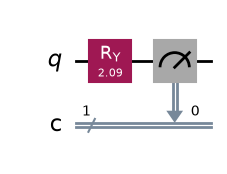

In [3]:
qc = QuantumCircuit(1, 1)

# Start with the qubit in |0>
# Apply a rotation gate to create a biased quantum state
qc.ry(2 * 3.14159 / 3, 0)

# Measure the qubit
qc.measure(0, 0)

# Display the circuit
qc.draw('mpl')


In [4]:
import math

theta = 2 * math.pi / 3

p0 = math.cos(theta / 2) ** 2
p1 = math.sin(theta / 2) ** 2

print("Predicted probability of 0:", round(p0, 2))
print("Predicted probability of 1:", round(p1, 2))
print("Predicted percentage of 0:", round(p0 * 100, 2), "%")
print("Predicted percentage of 1:", round(p1 * 100, 2), "%")

Predicted probability of 0: 0.25
Predicted probability of 1: 0.75
Predicted percentage of 0: 25.0 %
Predicted percentage of 1: 75.0 %


In [5]:
simulator = AerSimulator()

compiled_circuit = qc

job = simulator.run(compiled_circuit, shots=100)
result = job.result()

counts = result.get_counts()

print("Measurement results:", counts)
print("Number of shots:", sum(counts.values()))

Measurement results: {'1': 70, '0': 30}
Number of shots: 100


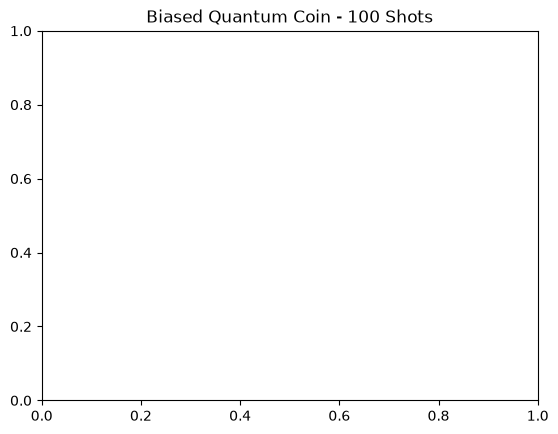

In [6]:
plot_histogram(counts)
plt.title("Biased Quantum Coin - 100 Shots")
plt.show()

In [7]:
total_shots = sum(counts.values())

zeros = counts.get('0', 0)
ones = counts.get('1', 0)

print("Number of zeros:", zeros)
print("Number of ones:", ones)

print("Observed percentage of 0:", round(zeros / total_shots * 100, 2), "%")
print("Observed percentage of 1:", round(ones / total_shots * 100, 2), "%")

Number of zeros: 30
Number of ones: 70
Observed percentage of 0: 30.0 %
Observed percentage of 1: 70.0 %


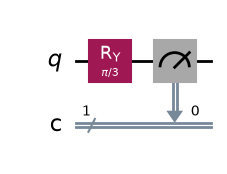

In [8]:
qc2 = QuantumCircuit(1, 1)

# Rotate by pi/3 to favor outcome 0
qc2.ry(math.pi / 3, 0)

qc2.measure(0, 0)

qc2.draw('mpl')

Second circuit results: {'0': 77, '1': 23}


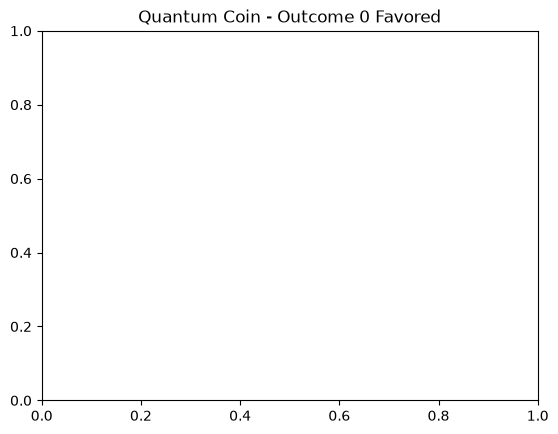

In [9]:
job2 = simulator.run(qc2, shots=100)
result2 = job2.result()

counts2 = result2.get_counts()

print("Second circuit results:", counts2)

plot_histogram(counts2)
plt.title("Quantum Coin - Outcome 0 Favored")
plt.show()

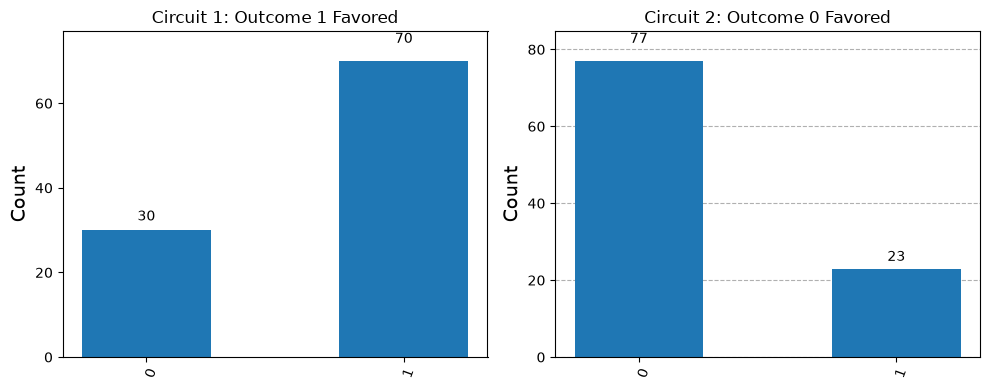

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

plot_histogram(counts, ax=axes[0])
axes[0].set_title("Circuit 1: Outcome 1 Favored")

plot_histogram(counts2, ax=axes[1])
axes[1].set_title("Circuit 2: Outcome 0 Favored")

plt.tight_layout()
plt.show()